# AdaBoost experiments

**Goal:** see how far AdaBoost gets on the classification task and which settings matter.

**Why AdaBoost:** there are 670 mostly numeric features, many of them redundant or constant. Boosted
shallow trees choose features as they go and don't need scaling, so they make a reasonable first
ensemble to try. AdaBoost also re-weights the examples it gets wrong, which may help with the
minority class (`output = 0`, about 15% of rows).

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

> **Metric correction (2026-10-15).** The leaderboard scores **ROC AUC on submitted
> probabilities**, not accuracy. The leaderboard showed it: an all-1s file scored exactly 0.50000,
> which is what AUC gives any constant prediction, and our 0/1-label hybrid scored only 0.586,
> although its known-subject AUC is about 0.89. Submitting the same model's *probabilities* scored
> **0.70**. This notebook has been re-run with AUC as the metric. Models are chosen by AUC,
> submissions contain P(class 1), and threshold tuning has been removed, because AUC does not depend
> on a threshold. Some tables still show accuracy for reference.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

## 1. Load data

In [2]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")
sample_solution = pd.read_csv("sample_solution.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
train.output.value_counts(normalize=True)

Train shape: (4584, 670)
Test shape : (1732, 669)


output
1    0.844895
0    0.155105
Name: proportion, dtype: float64

## 2. Check how train and test subjects overlap

**Hypothesis:** `subject` looks like an ID for a person or device. If the test set has subjects that
aren't in training, a random K-fold split will overestimate the leaderboard score.

In [3]:
subj = pd.DataFrame({
    "train": train.subject.value_counts(),
    "test": test.subject.value_counts(),
}).fillna(0).astype(int)
subj["train_frac_0"] = train.groupby("subject").output.apply(lambda s: (s == 0).mean()).round(3)
unseen = subj.index[subj.train == 0].tolist()
print("Subjects only in test:", unseen,
      f"-> {test.subject.isin(unseen).mean():.0%} of test rows")
subj

Subjects only in test: ['E', 'J'] -> 54% of test rows


,train,test,train_frac_0
subject,,,
A,380,59,0.029
B,513,78,0.140
C,361,71,0.244
D,420,83,0.062
E,0,312,NaN
F,330,60,0.221
G,518,88,0.508
H,181,33,0.138
I,663,124,0.038


**Interpretation:** subjects **E** and **J** appear only in the test set, and they make up over half of
it. The base rate also changes a lot between subjects (K has no 0s, G is about 50/50). So we:
- report **two CV scores**: stratified 5-fold (the optimistic one) and **GroupKFold by subject**
  (closer to what the unseen test subjects will look like). We pick settings using the grouped score.
- **leave `subject` out as a feature**, because it can't generalise to E and J.

## 3. Preprocessing

In [4]:
target = "output"
groups = train["subject"]

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    X = pd.get_dummies(X, columns=["state"], dtype=int)
    return X

X_full = prep(train)
X_test = prep(test).reindex(columns=X_full.columns, fill_value=0)
y = train[target]

# Constant columns carry no signal and only slow the tree search down
const_cols = X_full.columns[X_full.nunique() <= 1]
X_full = X_full.drop(columns=const_cols)
X_test = X_test.drop(columns=const_cols)
print(f"Dropped {len(const_cols)} constant columns -> {X_full.shape[1]} features")

Dropped 108 constant columns -> 564 features


## 4. Evaluation harness and majority-class baseline

The competition metric is **ROC AUC** (see the note at the top). A constant prediction, such as all
1s or the majority-class baseline, scores exactly 0.5. We report AUC under both CV schemes and keep
accuracy and macro-F1 for reference. Accuracy at the default threshold mostly shows how rarely a
model predicts class 0.

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
results = []

def evaluate(name, model):
    row = {"model": name}
    for cv_name, cv, kw in [("strat", skf, {}), ("group", gkf, {"groups": groups})]:
        s = cross_validate(model, X_full, y, cv=cv, n_jobs=-1,
                           scoring=["roc_auc", "accuracy", "f1_macro"], **kw)
        row[f"{cv_name}_auc"] = s["test_roc_auc"].mean()
        row[f"{cv_name}_auc_std"] = s["test_roc_auc"].std()
        row[f"{cv_name}_acc"] = s["test_accuracy"].mean()
        row[f"{cv_name}_f1m"] = s["test_f1_macro"].mean()
    results.append(row)
    return pd.Series(row)

evaluate("majority baseline", DummyClassifier(strategy="most_frequent"))

model            majority baseline
strat_auc                      0.5
strat_auc_std                  0.0
strat_acc                 0.844895
strat_f1m                 0.457964
group_auc                      0.5
group_auc_std                  0.0
group_acc                 0.852051
group_f1m                  0.45784
dtype: object

## 5. Experiment 1: default AdaBoost (decision stumps)

**Hypothesis:** AdaBoost with depth-1 stumps and 50 rounds will rank rows well on stratified CV (AUC
clearly above 0.5), but on unseen subjects it will be close to 0.5, because 50 single-split learners
on 500+ features will mostly pick up subject-specific patterns.

In [6]:
ada_default = AdaBoostClassifier(random_state=RANDOM_STATE)
evaluate("ada stumps, n=50, lr=1.0", ada_default)

model            ada stumps, n=50, lr=1.0
strat_auc                        0.677709
strat_auc_std                    0.022044
strat_acc                        0.847077
strat_f1m                        0.492495
group_auc                        0.497292
group_auc_std                     0.04032
group_acc                         0.84109
group_f1m                         0.45557
dtype: object

**Interpretation:** the hypothesis held. Default AdaBoost ranks rows clearly better than chance on
stratified CV (AUC **0.678**), but on unseen subjects it is at chance (grouped AUC **0.497**). Whatever
the stumps learn is specific to the subjects they were trained on.

## 6. Experiment 2: number of rounds (staged learning curve)

**Hypothesis:** more rounds help up to a point, and then AdaBoost starts fitting noisy or mislabeled
points (it is known to be sensitive to label noise). A lower learning rate should push that peak
later and make it smoother.

`staged_decision_function` scores every prefix of the ensemble, so one fit per fold gives the whole
AUC curve. We use the grouped folds. Earlier runs with 400 rounds peaked well before round 100, so
we stop at `N = 100`. That cuts the runtime from about 75 to about 20 minutes.

In [7]:
def staged_curve(model, n_estimators):
    aucs = np.zeros(n_estimators)
    for tr_idx, va_idx in gkf.split(X_full, y, groups):
        m = model.fit(X_full.iloc[tr_idx], y.iloc[tr_idx])
        for i, score in enumerate(m.staged_decision_function(X_full.iloc[va_idx])):
            aucs[i] += roc_auc_score(y.iloc[va_idx], score)
    return aucs / gkf.get_n_splits()

N = 100
curves = {}
for depth in [1, 2, 3]:
    for lr in [1.0, 0.3, 0.1]:
        m = AdaBoostClassifier(DecisionTreeClassifier(max_depth=depth),
                               n_estimators=N, learning_rate=lr, random_state=RANDOM_STATE)
        curves[(depth, lr)] = staged_curve(m, N)
        best = curves[(depth, lr)].argmax()
        print(f"depth={depth} lr={lr:<4} best grouped AUC={curves[(depth, lr)][best]:.4f} at n={best + 1}")

depth=1 lr=1.0  best grouped AUC=0.5144 at n=2


depth=1 lr=0.3  best grouped AUC=0.5239 at n=5


depth=1 lr=0.1  best grouped AUC=0.5241 at n=19


depth=2 lr=1.0  best grouped AUC=0.5130 at n=33


depth=2 lr=0.3  best grouped AUC=0.5143 at n=9


depth=2 lr=0.1  best grouped AUC=0.5503 at n=12


depth=3 lr=1.0  best grouped AUC=0.5428 at n=97


depth=3 lr=0.3  best grouped AUC=0.5505 at n=7


depth=3 lr=0.1  best grouped AUC=0.5328 at n=19


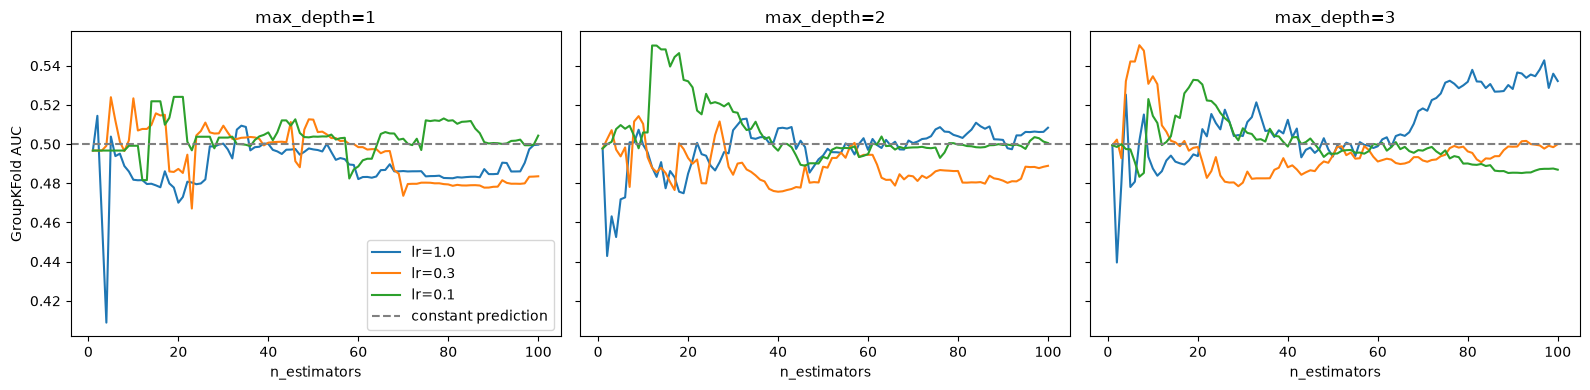

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, depth in zip(axes, [1, 2, 3]):
    for lr in [1.0, 0.3, 0.1]:
        ax.plot(np.arange(1, N + 1), curves[(depth, lr)], label=f"lr={lr}")
    ax.axhline(0.5, color="grey", ls="--", label="constant prediction")
    ax.set_title(f"max_depth={depth}")
    ax.set_xlabel("n_estimators")
axes[0].set_ylabel("GroupKFold AUC")
axes[0].legend()
plt.tight_layout()

**Interpretation:** partly right. Every curve peaks early: 8 of 9 settings peak by round 33, and more
rounds never help after that. A lower learning rate doesn't reliably move the peak later (depth 3
peaks at n=97 with lr 1.0, n=7 with lr 0.3, and n=19 with lr 0.1). Deeper trees do a little better
than stumps: the best grouped AUC is **0.55** (depth 3, lr 0.3, n=7, or depth 2, lr 0.1, n=12),
vs 0.51–0.52 for stumps.

Under accuracy this section looked flat at the baseline. AUC shows a weak ranking signal on unseen
subjects, about 0.55, but it is small next to the spread between folds (grouped AUC std 0.09 in
section 7).

## 7. Experiment 3: confirm the best setting on both CV schemes

In [9]:
(best_depth, best_lr), best_curve = max(curves.items(), key=lambda kv: kv[1].max())
best_n = int(best_curve.argmax()) + 1
print(f"Best: depth={best_depth}, lr={best_lr}, n_estimators={best_n}")

ada_best = AdaBoostClassifier(DecisionTreeClassifier(max_depth=best_depth),
                              n_estimators=best_n, learning_rate=best_lr,
                              random_state=RANDOM_STATE)
evaluate(f"ada depth={best_depth}, n={best_n}, lr={best_lr}", ada_best)
pd.DataFrame(results).set_index("model").round(4)

Best: depth=3, lr=0.3, n_estimators=7


,strat_auc,strat_auc_std,strat_acc,strat_f1m,group_auc,group_auc_std,group_acc,group_f1m
model,,,,,,,,
majority baseline,0.5000,0.0000,0.8449,0.4580,0.5000,0.0000,0.8521,0.4578
"ada stumps, n=50, lr=1.0",0.6777,0.0220,0.8471,0.4925,0.4973,0.0403,0.8411,0.4556
"ada depth=3, n=7, lr=0.3",0.6648,0.0058,0.8484,0.4910,0.5505,0.0902,0.8495,0.4606


## 8. Experiment 4: ranking on held-out subjects

**Hypothesis:** on subjects it hasn't seen, the model's scores will barely separate the classes. AUC
on the held-out subjects, and within each held-out subject, will be close to 0.5.

In [10]:
gss_tr, gss_va = next(GroupKFold(n_splits=4).split(X_full, y, groups))
ada_best.fit(X_full.iloc[gss_tr], y.iloc[gss_tr])
va = pd.DataFrame({"y": y.iloc[gss_va].values, "subject": groups.iloc[gss_va].values,
                   "p": ada_best.predict_proba(X_full.iloc[gss_va])[:, 1]})
print("Held-out subjects:", sorted(va.subject.unique()))
print(f"AUC on held-out subjects: {roc_auc_score(va.y, va.p):.3f}")
print("Within-subject AUC:", {s: round(roc_auc_score(d.y, d.p), 3) for s, d in va.groupby("subject")
                              if d.y.nunique() > 1})
print(f"Predicted P(class 1) ranges from {va.p.min():.3f} to {va.p.max():.3f}")

Held-out subjects: ['C', 'I']
AUC on held-out subjects: 0.455
Within-subject AUC: {'C': 0.452, 'I': 0.668}
Predicted P(class 1) ranges from 0.568 to 0.881


**Interpretation:** the hypothesis mostly held. On the held-out subjects (C and I), pooled AUC is
**0.455**, below chance. Inside each subject it is mixed: I 0.668, C 0.452. Predicted probabilities
only span 0.57–0.88. The pooled AUC is lower than I's own AUC, so putting the two subjects together
hurts. That is a sign the score *levels* don't reflect how different their class-0 rates are
(C 24%, I 4%).

## 9. Feature importance

The grade includes 10% for explainability. We look at two views:
- **Impurity importance** (`feature_importances_`): cheap to compute, but biased toward features with
  many unique values.
- **Permutation importance** on the held-out subjects: how much **AUC** drops when a feature is
  shuffled. This is more reliable, and it is measured on unseen subjects.

**Hypothesis:** a small set of features does most of the work, because AdaBoost with shallow trees
only ever splits on a few of them.

Features ever used: 30 / 564


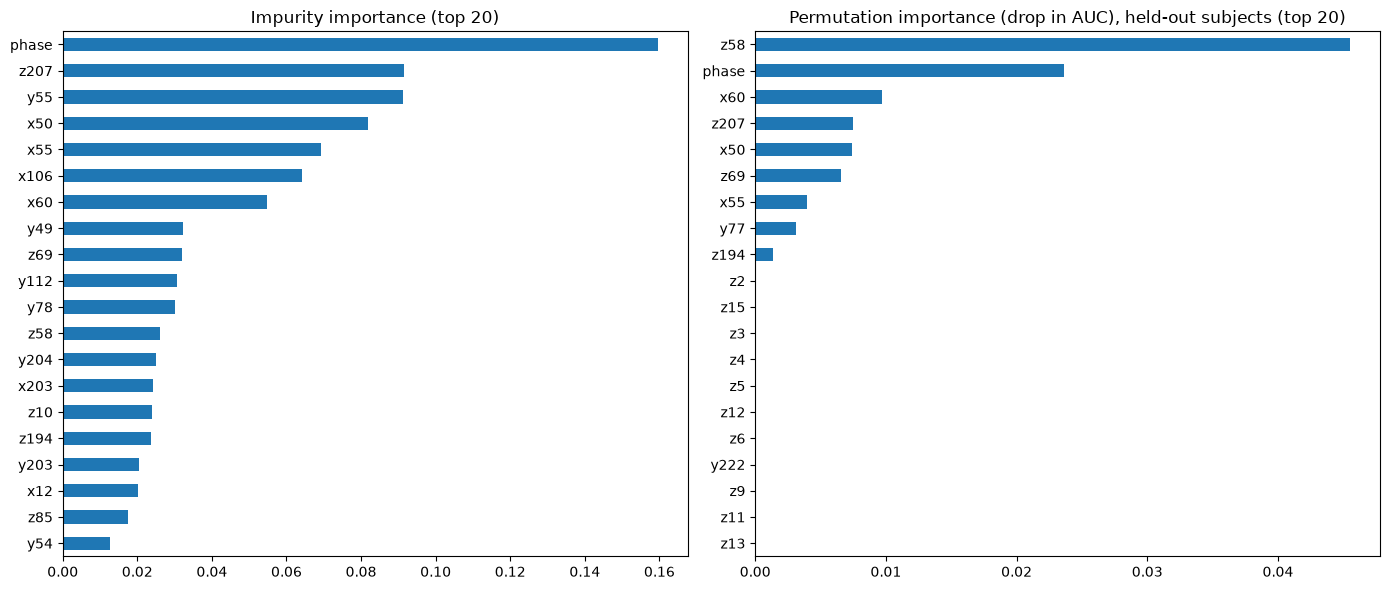

In [11]:
imp = pd.Series(ada_best.feature_importances_, index=X_full.columns).sort_values(ascending=False)
print(f"Features ever used: {(imp > 0).sum()} / {len(imp)}")

perm = permutation_importance(ada_best, X_full.iloc[gss_va], y.iloc[gss_va],
                              scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_full.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(20)[::-1].plot.barh(ax=axes[0], title="Impurity importance (top 20)")
perm_imp.head(20)[::-1].plot.barh(ax=axes[1], title="Permutation importance (drop in AUC), held-out subjects (top 20)")
plt.tight_layout()

**Interpretation:** the hypothesis held, and the two views partly agree: 8 of the top 20 features
are in both lists (`phase`, `x50`, `x55`, `x60`, `z194`, `z207`, `z58`, `z69`).
- By impurity, `phase` (0.16), `z207`, `y55` and `x50` lead. Only **30 of 564** features are used at
  all.
- By permutation on the held-out subjects (drop in AUC), `z58` (0.046) and `phase` (0.024) lead.
- Several features have **negative** permutation importance (`z54` −0.051, `y78` −0.035,
  `y49` −0.027). Shuffling them *raises* AUC on unseen subjects, so the model's use of them actively
  hurts transfer.

Under accuracy, every permutation importance was about 0, because the model predicted all 1s. AUC
makes this view informative.

## 10. Fit on all training data and write a submission (probabilities)

In [12]:
ada_best.fit(X_full, y)
submission = sample_solution.copy().astype({"output": float})
submission["output"] = ada_best.predict_proba(X_test)[:, 1]
submission.to_csv("submission_adaboost_proba.csv", index=False)
submission.output.describe().round(3)

count    1732.000
mean        0.840
std         0.049
min         0.360
25%         0.845
50%         0.848
75%         0.881
max         0.881
Name: output, dtype: float64

## Summary and next steps

**Result:** AdaBoost ranks rows on stratified CV (AUC 0.66–0.68) but barely on unseen subjects. Its
best grouped AUC is **0.55** (depth 3, lr 0.3, 7 rounds), with a large spread between folds.
`submission_adaboost_proba.csv` contains probabilities. The original 0/1-label file
(`submission_adaboost.csv`) scored **0.503** on the leaderboard, almost exactly what a constant
gets.

**What we learned:**
- **The metric matters.** Under accuracy, AdaBoost looked like "always predicts 1". Under AUC there
  is a weak ranking signal, and the feature importances become readable.
- The raw features mostly encode *subject identity*. Some of them (`z54`, `y78`, `y49`) actively
  hurt ranking on unseen subjects.
- Tuning more boosting hyperparameters won't fix that. The later notebooks try per-subject
  normalisation (`random_forest.ipynb`, which raises the forest's grouped AUC to 0.58–0.59) and a
  hybrid model for subjects that are in the training data. The final leaderboard results are in
  `automl.ipynb` §7.

*Runtime:* about 15 minutes (section 6 dominates).